# ETCC のエネルギースペクトルとバックプロジェクション

再構成 ROOT を読み、**追加カットなし・fiducial のみ・dE/dx のみ・両方・両方＋α整合性**の5条件を比較します。
エネルギースペクトルは $E_g$、$K_e$、$E_0=E_g+K_e$ を同じビンで重ね、方向図は Compton cone と飛跡を使う ETCC の両方を描きます。
線源の実測位置から ARM も求めます。**Eg の追加カットはかけません。**

- 入力: `smile3_reconstruct` の `Reconstruct/single_hit` と `TOT_Skewness/tot_skewness`。
- 必要な列: `evt_id`、`Eg`、`Ke`、`E0`、`Pe`、`Pg`、`Vi`、`cos_phi`、`has_track`、`delta_cos_alpha` と、飛跡の `Len`、`track_min/max`。
- 同じイベント番号が別runでも現れるので、**ファイルごとに evt_id で対応付け、Pe の一致も検証**します。
- PyROOT・numpy・matplotlib を使えるカーネルで実行してください。この環境では `/usr/bin/python3` を使います。

## 1. 再構成 ROOT の用意

生データからの変換・再構成は、このノートブックの描画と分けて一度だけ実行します。
第1段階は `smile3_etcc_raw`、第2段階は `smile3_reconstruct`。較正は測定に対応した設定を使ってください。

```bash
python3 run_script/run_chain.py smile3_reconstruct \
  --root-input /path/to/etcc_raw.root -o /path/to/etcc_recon.root
```

分割した ROOT も入力できます。古い ROOT の tot_skewness に `evt_id`・`track_min/max` がない場合は再構成し直します。
追加カットなしだけを描く場合は、コマンド行の `compare_etcc_cuts.py --baseline-only` で古い ROOT も読めます。

In [1]:
import sys, glob, json, shlex, subprocess
from pathlib import Path
import numpy as np
import ROOT
from IPython.display import Image, Markdown, display
ROOT.gROOT.SetBatch(True)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'run_script/run_chain.py').is_file())
SCRIPT = REPO / 'scripts/analysis/compare_etcc_cuts.py'
PYTHON = sys.executable
print('Repository:', REPO)
print('Python:', PYTHON)

Repository: /home/onoda/ANLNext/Erica_git_dev/EricaNext
Python: /usr/bin/python3


## 2. 入力と出力

以下は2026年11月の解析例です。パスは各自の環境に合わせて変更してください。
`SELECTED_RUNS` で実行するデータを選びます。`expected_files` は分割 ROOT の取りこぼしを防ぐ確認数です。
1ファイル/run の入力なら1、確認不要の場合は `None` にします。
ROOT、PNG、選別条件の JSON はリポジトリ外の `OUT` に保存します。

| データ | 線源位置 (X, Y, Z) [mm] | 条件 |
|---|---|---|
| 20261116 run03＋06 | (−380, −1090, −1412) | 天頂角約39°の測定。方向図の黒い＋は検出器中心 (0, 0, 160) mm から見た方向 |
| 20261115 run03 | (0, 0, −152) | 天頂角0°。近距離なので ARM は各イベントの Pe と線源の実測位置から計算 |

線源位置や較正値を別のrunに流用せず、その測定で確かめた値を指定してください。

In [2]:
DATA_ROOT = Path('/home/onoda/ericanext_out')
OUT = DATA_ROOT / 'tutorials/ETCC_CutComparison'
DATASETS = {
    '20261116_run03_06': {
        'patterns': [str(DATA_ROOT / '20261116_v2/etcc_recon*/*.root')],
        'source_mm': (-380.0, -1090.0, -1412.0),
        'label': '20261116 run03+06 (source zenith 39 deg)',
        'expected_files': 12,
    },
    '20261115_run03': {
        'patterns': [str(DATA_ROOT / '20261115_selected/etcc_recon_20261115_run03/*.root')],
        'source_mm': (0.0, 0.0, -152.0),
        'label': '20261115 run03 (source zenith 0 deg)',
        'expected_files': 104,
    },
}
SELECTED_RUNS = ['20261116_run03_06', '20261115_run03']
INPUTS = {}
for name in SELECTED_RUNS:
    item = DATASETS[name]
    files = sorted(set(f for pattern in item['patterns'] for f in glob.glob(pattern)))
    if not files:
        raise FileNotFoundError(f'{name}: no reconstructed ROOT files')
    expected = item['expected_files']
    if expected is not None and len(files) != expected:
        raise ValueError(f'{name}: expected {expected} files, got {len(files)}; check reconstruction completion')
    if not all(Path(f).is_absolute() for f in files) or not OUT.is_absolute():
        raise ValueError('Use absolute input and output paths')
    INPUTS[name] = files
    print(name, len(files), 'files ->', OUT / name)

20261116_run03_06 12 files -> /home/onoda/ericanext_out/tutorials/ETCC_CutComparison/20261116_run03_06
20261115_run03 104 files -> /home/onoda/ericanext_out/tutorials/ETCC_CutComparison/20261115_run03


## 3. カットの定義とパラメータ

比較の基準は飛跡あり (`has_track == 1`)、$K_e>0$、必要な値が有限の事象です。
灰色のスペクトルには全 single_hit も重ねます。上流の PSA_Event による1ヒット選別とエネルギー条件はそのままです。

| パラメータ | 説明 | 単位 |
|---|---|---|
| `MAP_E0_KEV` | 方向図・ARM の E0 窓。**スペクトルには適用しない** | keV |
| `ALPHA_MAX_DELTA_COS` | $|\cos\alpha_{geo}-\cos\alpha_{kin}|$ の上限（等号は除外）。角度そのものの上限ではない | 無次元 |
| `FIDUCIAL_MARGIN_MM` | 飛跡の外接範囲全体を外壁・ドリフト領域の両端から内側に離す距離 | mm |
| `LENGTH_SCALE` | SMILE-2+ の dE/dx 帯の長さを掛ける係数。既定は2 atm/3 atmの仮定 | 無次元 |
| `SKY_BINS` | 方向図の1軸のビン数。24なら範囲−90～90°を7.5°幅で分割 | bins |

fiducial の既定値は $-148.6<x,y<148.6$ mm、$15<z<312$ mm。
Pe だけでなく、飛跡の `track_min/max` が範囲内にあることを要求します。

dE/dx は $K_e=5\text{–}400$ keV に対し、$s=$ `LENGTH_SCALE` として

$$s[913.9(K_e/1000)^2+2.2]<L<s[1975.9(K_e/1000)^{1.4}+7.0],\quad L<270s\ {\rm mm}.$$

ガス組成は同じと確認されていますが、この帯は**SMILE-3 の実測で確定した帯ではありません**。既定の長さ上限は180 mmです。
カットを変えた場合は、下の描画セルから再実行します。

In [3]:
MAP_E0_KEV = (630.0, 700.0)
ALPHA_MAX_DELTA_COS = 0.5
FIDUCIAL_MARGIN_MM = 5.0
LENGTH_SCALE = 2.0 / 3.0
SKY_BINS = 24

## 4. 描画する

共通の解析スクリプトを実行します。再構成・較正は実行しません。
同じ出力先のPNGとJSONは、指定した条件で更新します。
入力の不整合、重複イベントID、Peの不一致はエラーで止まります。

In [4]:
for name in SELECTED_RUNS:
    item = DATASETS[name]
    cmd = [PYTHON, str(SCRIPT), *INPUTS[name], '--out', str(OUT / name),
           '--src', *map(str, item['source_mm']), '--label', item['label'],
           '--emin', str(MAP_E0_KEV[0]), '--emax', str(MAP_E0_KEV[1]),
           '--alpha', str(ALPHA_MAX_DELTA_COS), '--margin', str(FIDUCIAL_MARGIN_MM),
           '--len-scale', str(LENGTH_SCALE), '--bins', str(SKY_BINS)]
    print(shlex.join(cmd), flush=True)
    subprocess.run(cmd, check=True, cwd=REPO)
SUMMARIES = {name: json.loads((OUT / name / 'selection_summary.json').read_text())
             for name in SELECTED_RUNS}

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/analysis/compare_etcc_cuts.py /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run03/etcc_recon_20261116_run03.part000.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run03/etcc_recon_20261116_run03.part001.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part000.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part001.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part002.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part003.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part004.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part005.root /home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/analysis/compare_etcc_cuts.py /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part000.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part001.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part002.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part003.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part004.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part005.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part006.root /home/onoda/ericanext_out/20261115_selected/etcc_recon_20261115_run03/etcc_recon_20261115_run03.part007.root /home/onoda/ericanext_out/202

/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run03/etcc_recon_20261116_run03.part000.root 40256 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run03/etcc_recon_20261116_run03.part001.root 39934 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part000.root 56430 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part001.root 56457 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part002.root 46927 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part003.root 16795 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part004.root 18608 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part005

## 5. 残存イベント数

スペクトルの件数、E0窓と $|\cos\phi|\le1$ を満たす件数、ETCC方向図の上半球に入る件数を区別します。
ARM の中央値・四分位範囲 (IQR) は度で表示します。IQR はフィットした角度分解能ではありません。
入力ファイル・選別条件・件数は `selection_summary.json` に残ります。

In [5]:
for name, result in SUMMARIES.items():
    rows = [f'**{name}**', '',
            '|条件|スペクトル|E0窓|上半球|ARM中央値 [deg]|IQR [deg]|',
            '|---|---:|---:|---:|---:|---:|']
    for row in result['cuts']:
        med = row['ARM_median_deg']
        iqr = row['ARM_IQR_deg']
        med_text = '—' if med is None else f'{med:.1f}'
        iqr_text = '—' if iqr is None else f'{iqr:.1f}'
        rows.append(f"|{row['cut']}|{row['spectrum_events']:,}|{row['E0_window_events']:,}|"
                    f"{row['upper_hemisphere_events']:,}|{med_text}|{iqr_text}|")
    display(Markdown('\n'.join(rows)))

**20261116_run03_06**

|条件|スペクトル|E0窓|上半球|ARM中央値 [deg]|IQR [deg]|
|---|---:|---:|---:|---:|---:|
|Track, no additional cut|381,229|23,114|20,026|37.2|49.4|
|Fiducial only|155,395|11,849|10,756|33.9|46.5|
|dE/dx only|48,409|5,783|5,295|25.2|45.3|
|Fiducial + dE/dx|36,735|4,530|4,242|24.8|43.0|
|Fiducial + dE/dx + |delta cos alpha| < 0.5|20,408|2,742|2,613|19.9|37.4|

**20261115_run03**

|条件|スペクトル|E0窓|上半球|ARM中央値 [deg]|IQR [deg]|
|---|---:|---:|---:|---:|---:|
|Track, no additional cut|2,235,404|247,040|226,773|43.3|40.7|
|Fiducial only|1,311,773|142,710|135,402|39.2|38.9|
|dE/dx only|508,384|62,274|57,299|36.8|40.8|
|Fiducial + dE/dx|402,868|49,272|46,139|34.9|39.8|
|Fiducial + dE/dx + |delta cos alpha| < 0.5|211,702|28,752|27,446|28.2|37.5|

## 6. エネルギースペクトル

左から Eg、Ke、E0。5 keV/bin、縦軸対数、規格化しない実数です。
**Eg カットも E0 窓もかけていません**。dE/dx の Ke 範囲は、そのカットに含まれます。

**20261116_run03_06**

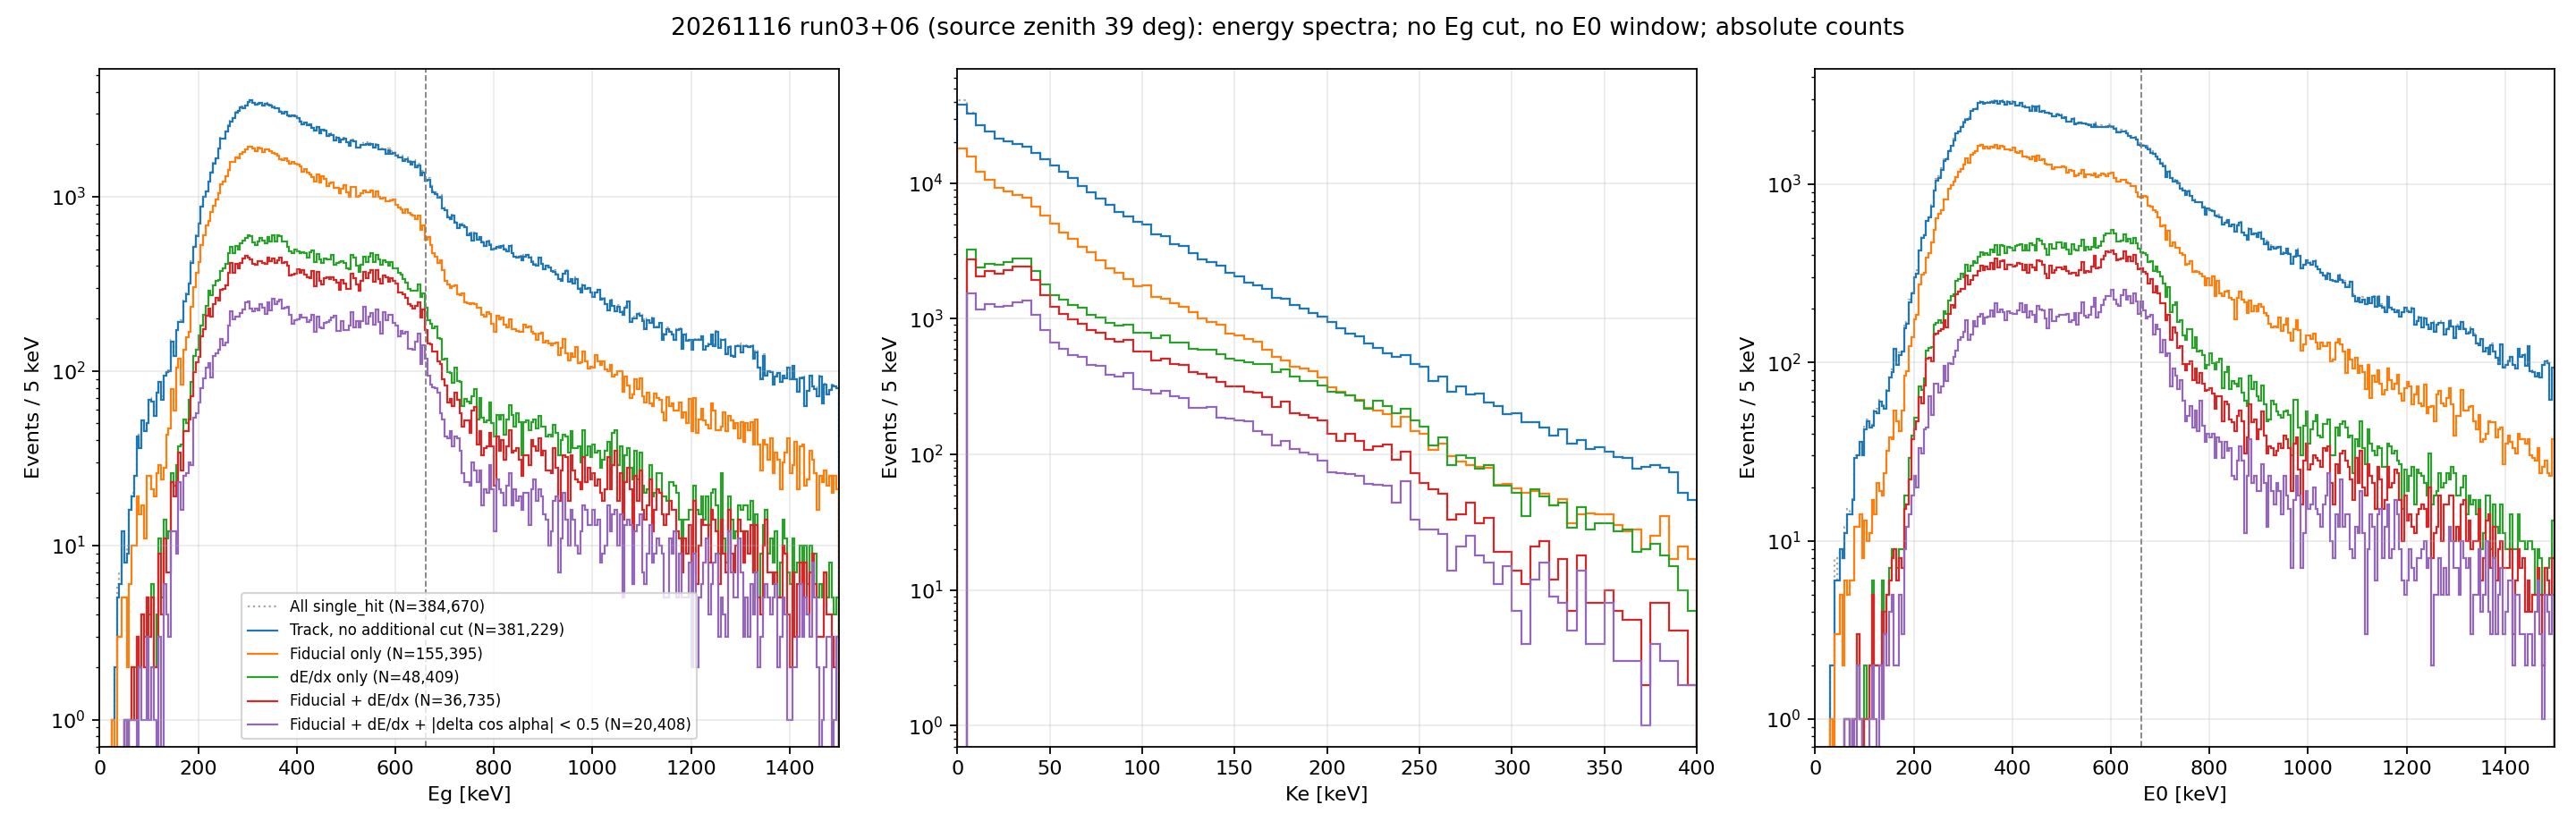

**20261115_run03**

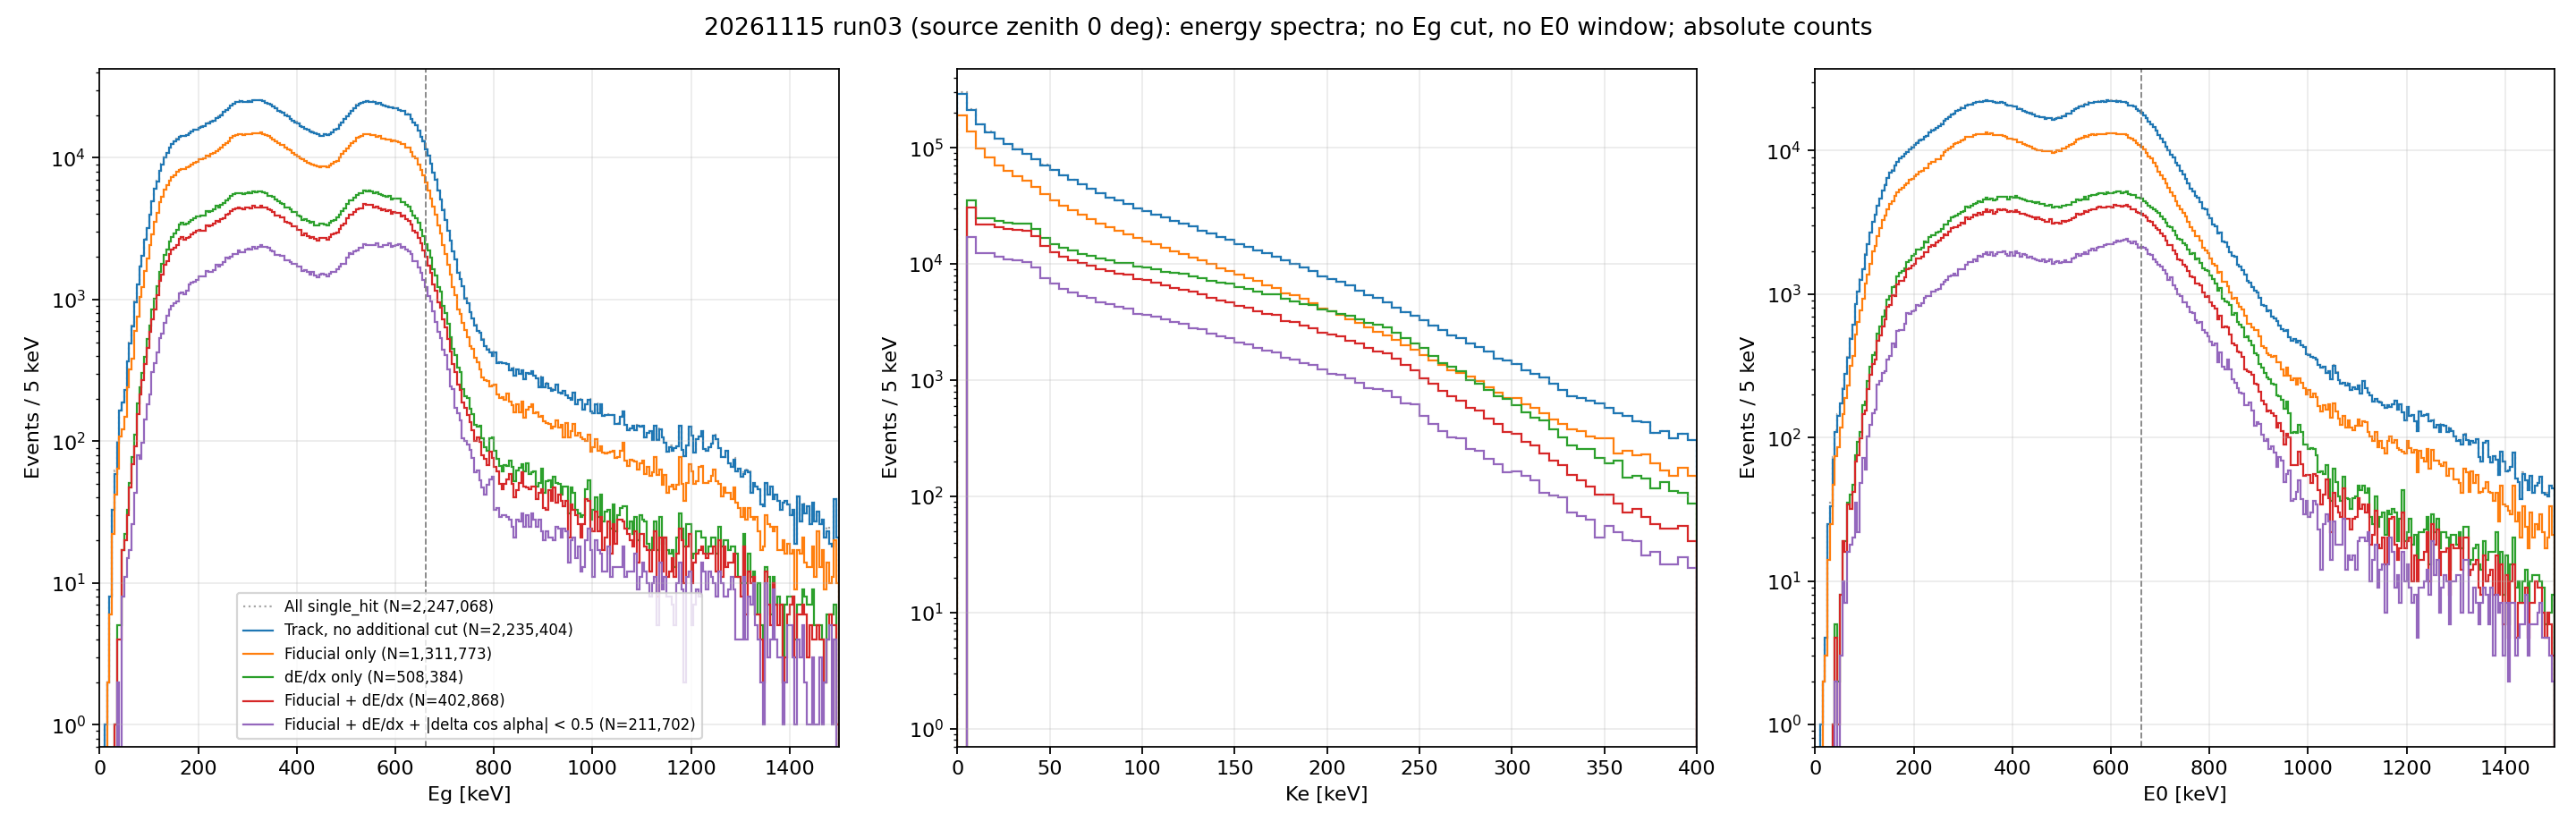

In [6]:
for name in SELECTED_RUNS:
    display(Markdown(f'**{name}**'))
    display(Image(filename=str(OUT / name / 'energy_cut_comparison.png')))

## 7. 各カット後のバックプロジェクションと ARM

各段は左から Compton cone（飛跡方向を使わない）、ETCC（飛跡方向を使う）、ARM。
上から追加カットなし、fiducial のみ、dE/dx のみ、両方、両方＋α整合性です。

- 方向図の半径は天頂角 $\theta$、横軸 $\theta\cos\varphi$、縦軸 $\theta\sin\varphi$ [deg]。
  天頂は −Z、+X は東、+Y は南。黒い＋は実測線源の方向です。
- ETCC の線源方向は $-V_i$。Compton cone は $P_e-P_g$ を軸として散乱角 $\phi$ の円周を360点で積分し、1点の重みを1/360にします。
  上半球で切るので cone の積算値はイベント数そのものとは一致しません。
- ARM は $\angle(P_e-P_{src},P_g-P_e)-\phi$ [deg]。近距離の線源にも各イベントの Pe を使います。
- 生カウントの方向図であり、等立体角ビンへの変換・検出効率の補正は行っていません。

`COMMON_COLOR_SCALE=False` は形を見比べるため各段で色スケールを合わせます。
`True` はカット間で同じ色スケールを使い、絶対件数の減少を見比べます。

**20261116_run03_06**

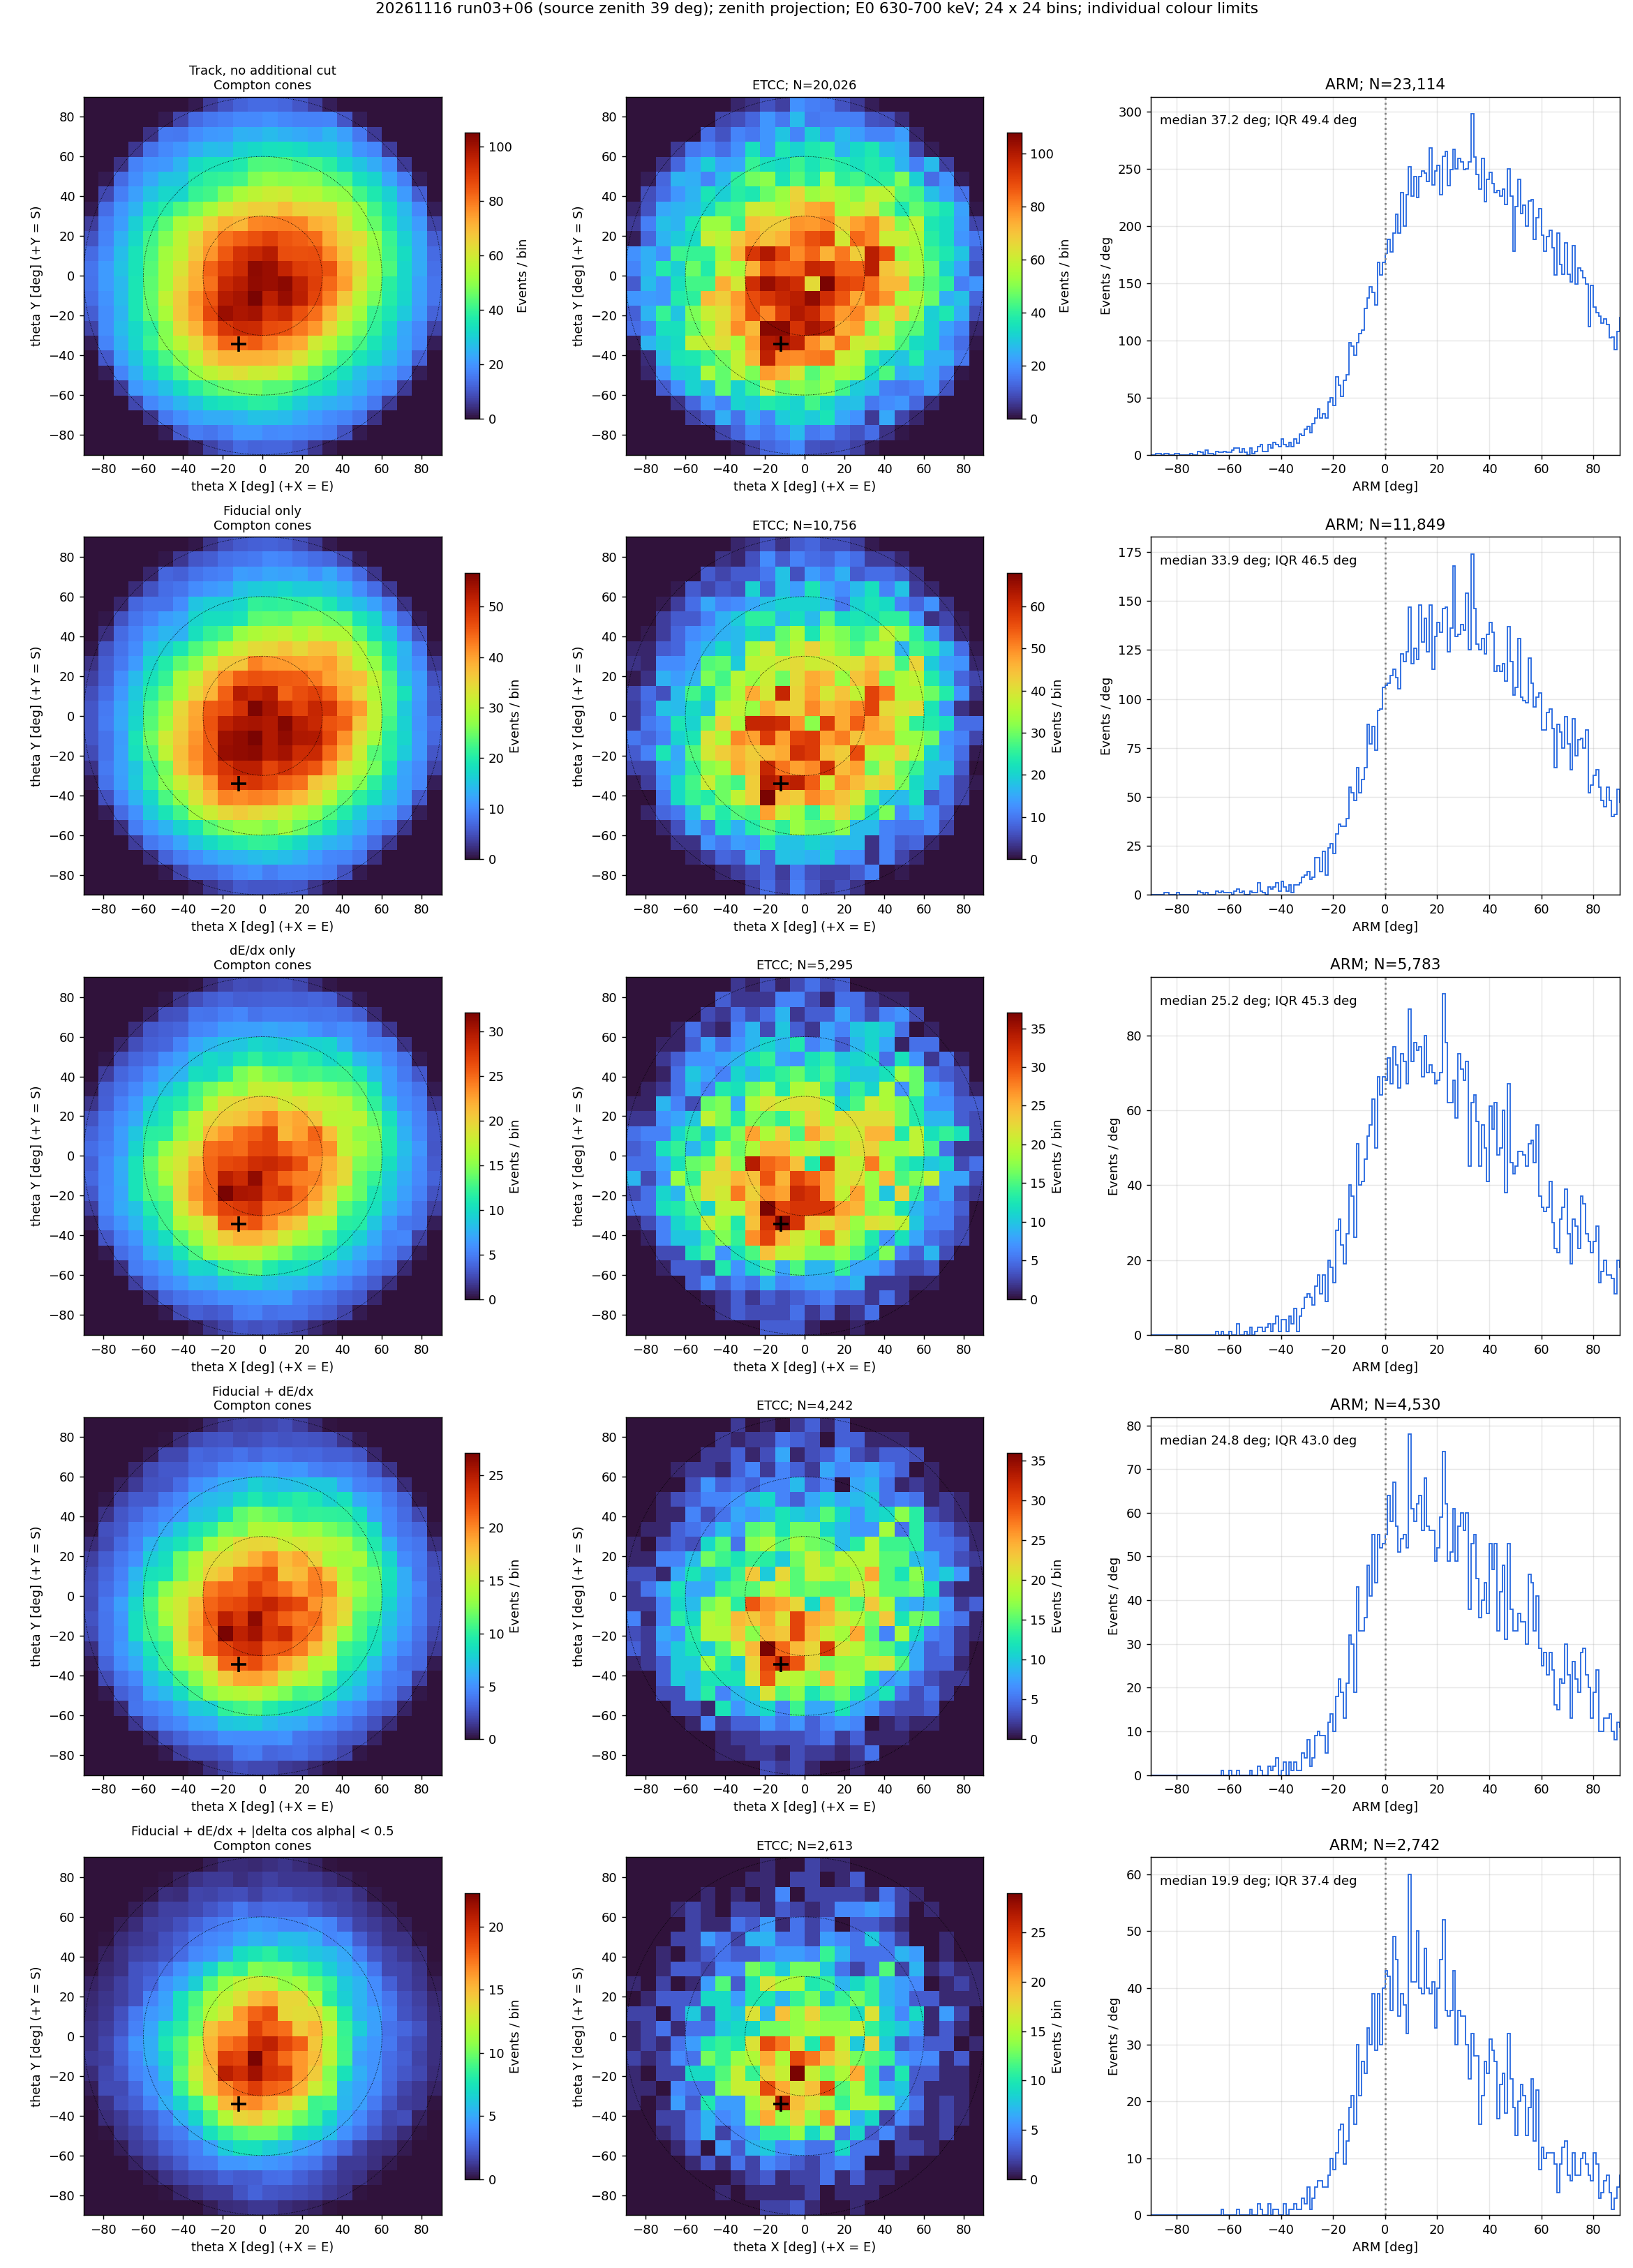

**20261115_run03**

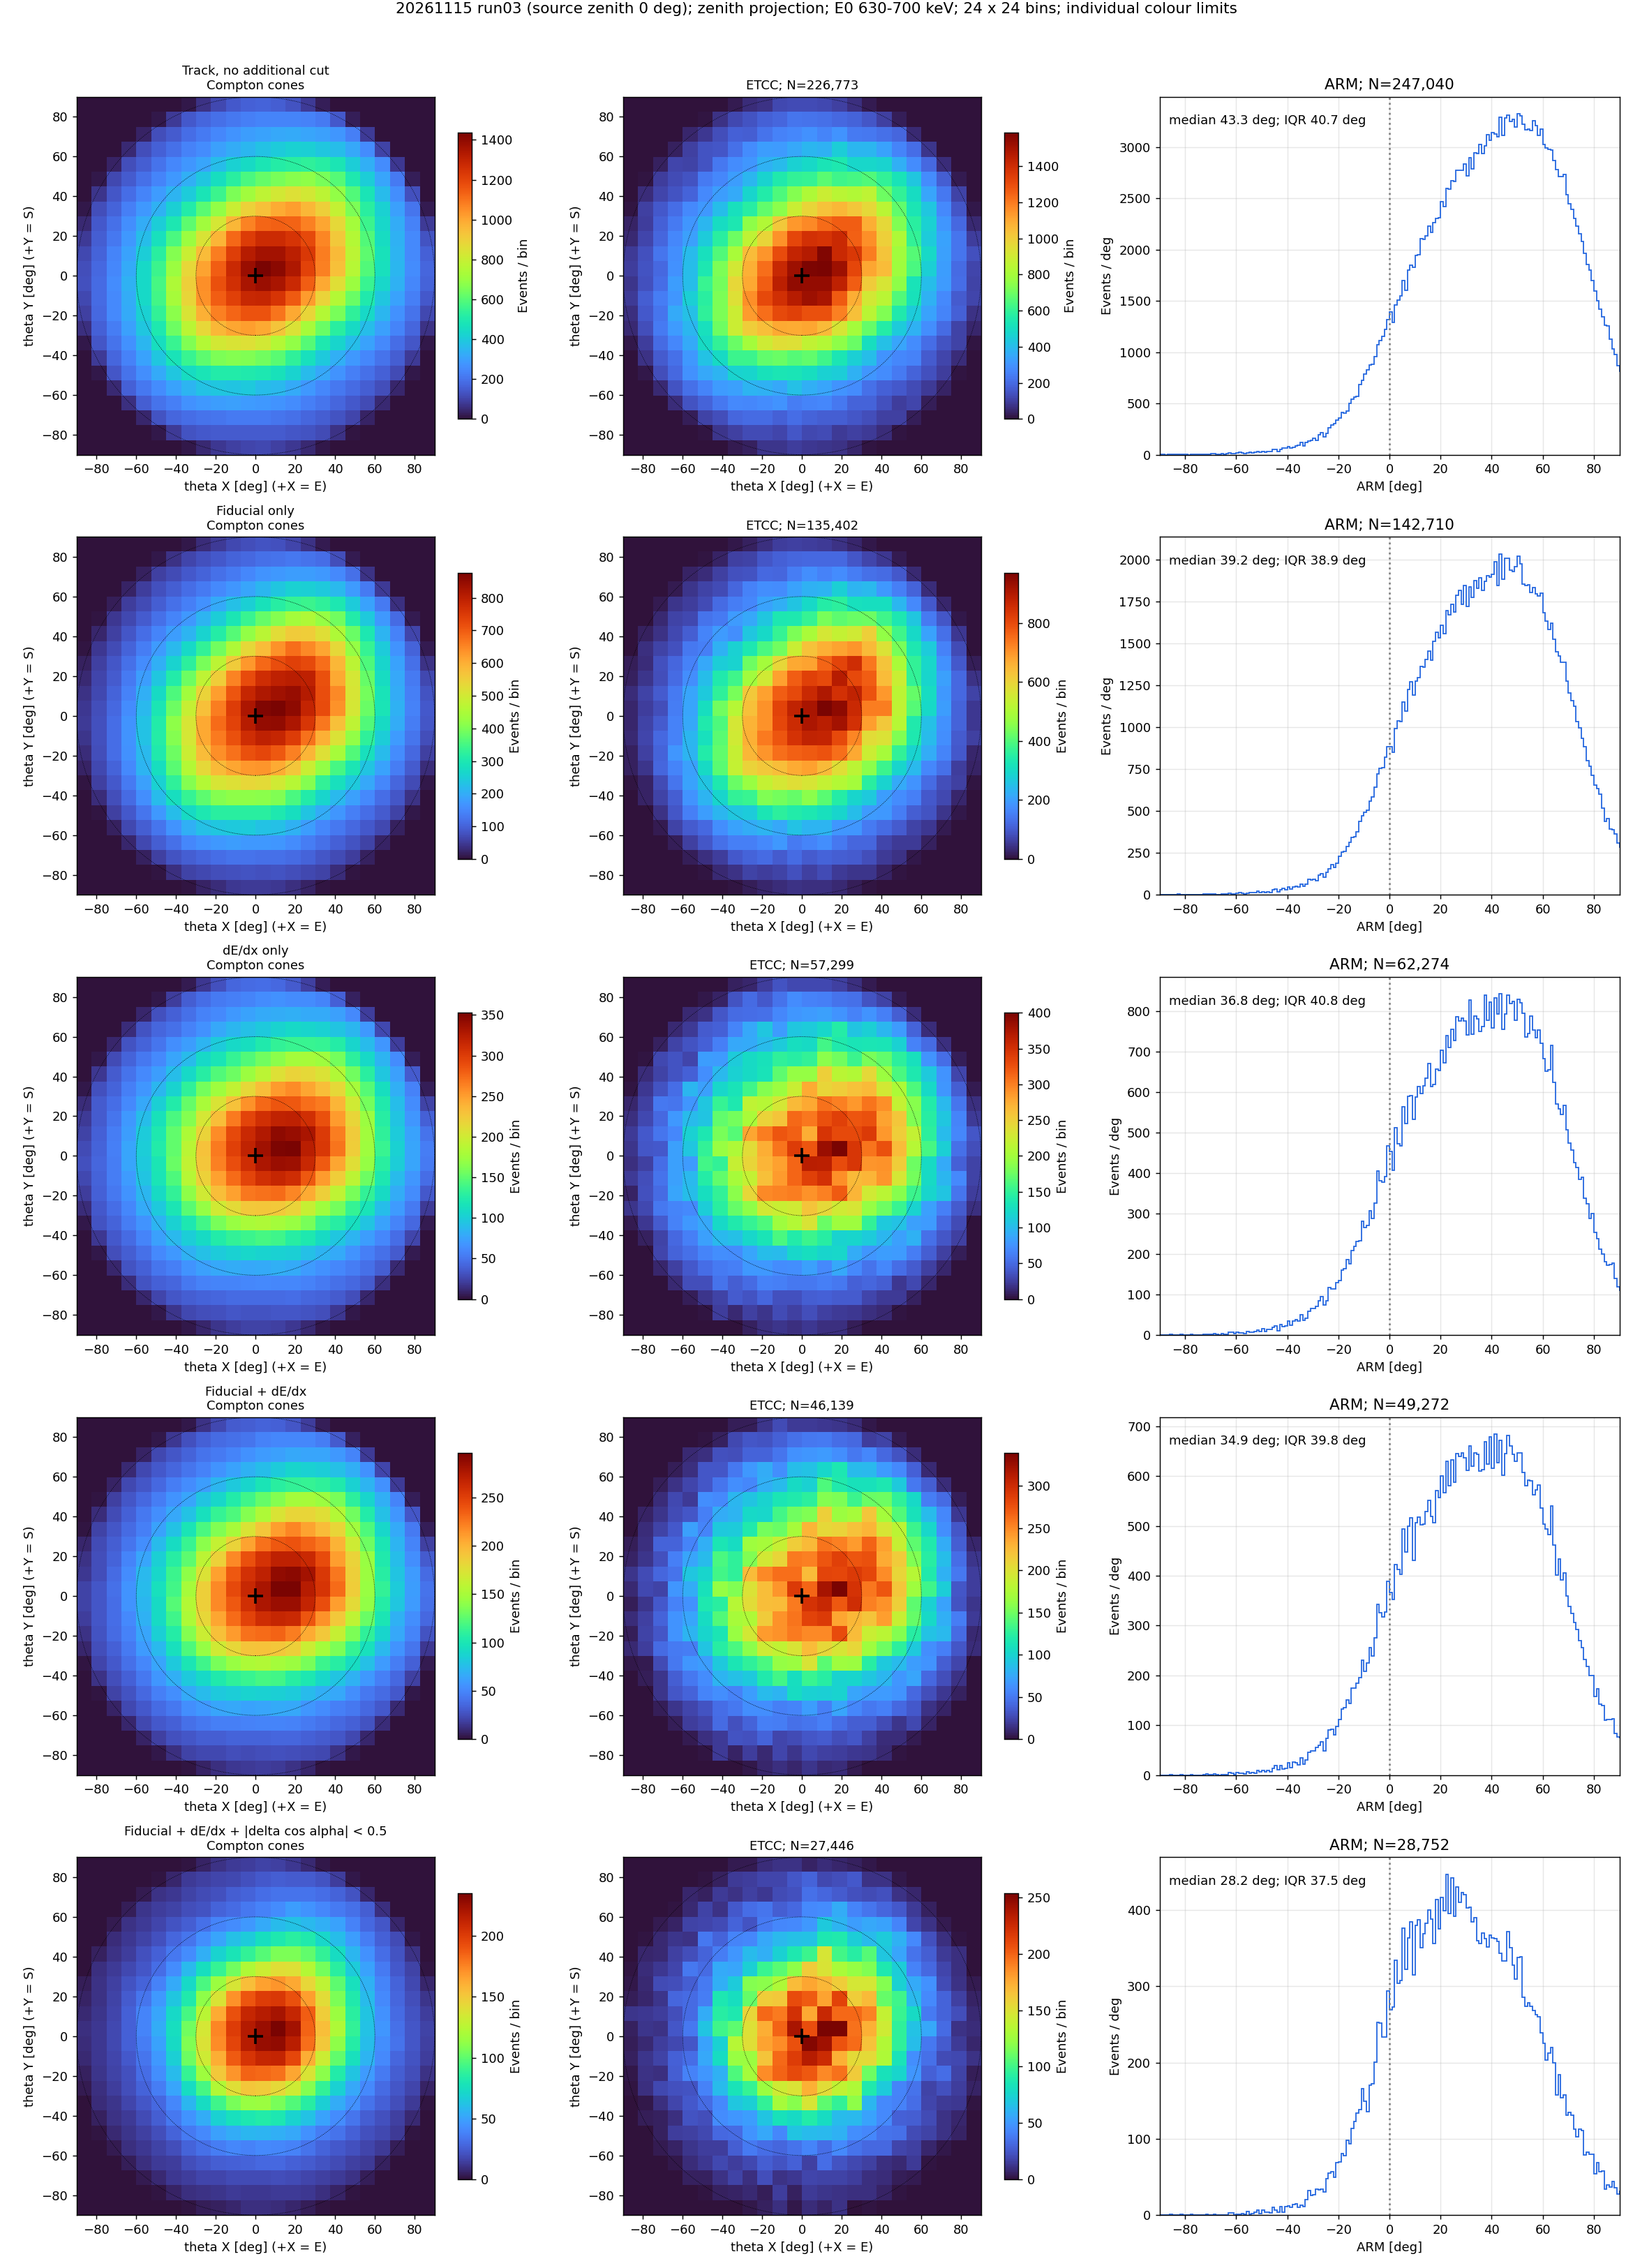

In [7]:
COMMON_COLOR_SCALE = False
map_file = ('backprojection_cut_comparison.png' if COMMON_COLOR_SCALE
            else 'backprojection_cut_comparison_autoscale.png')
for name in SELECTED_RUNS:
    display(Markdown(f'**{name}**'))
    display(Image(filename=str(OUT / name / map_file)))

## 8. 1条件だけ大きく表示する

`CUT_TO_SHOW` は0:追加なし、1:fiducial、2:dE/dx、3:両方、4:両方＋α整合性。
単独図の色スケールは各条件に合わせています。

**20261116_run03_06**

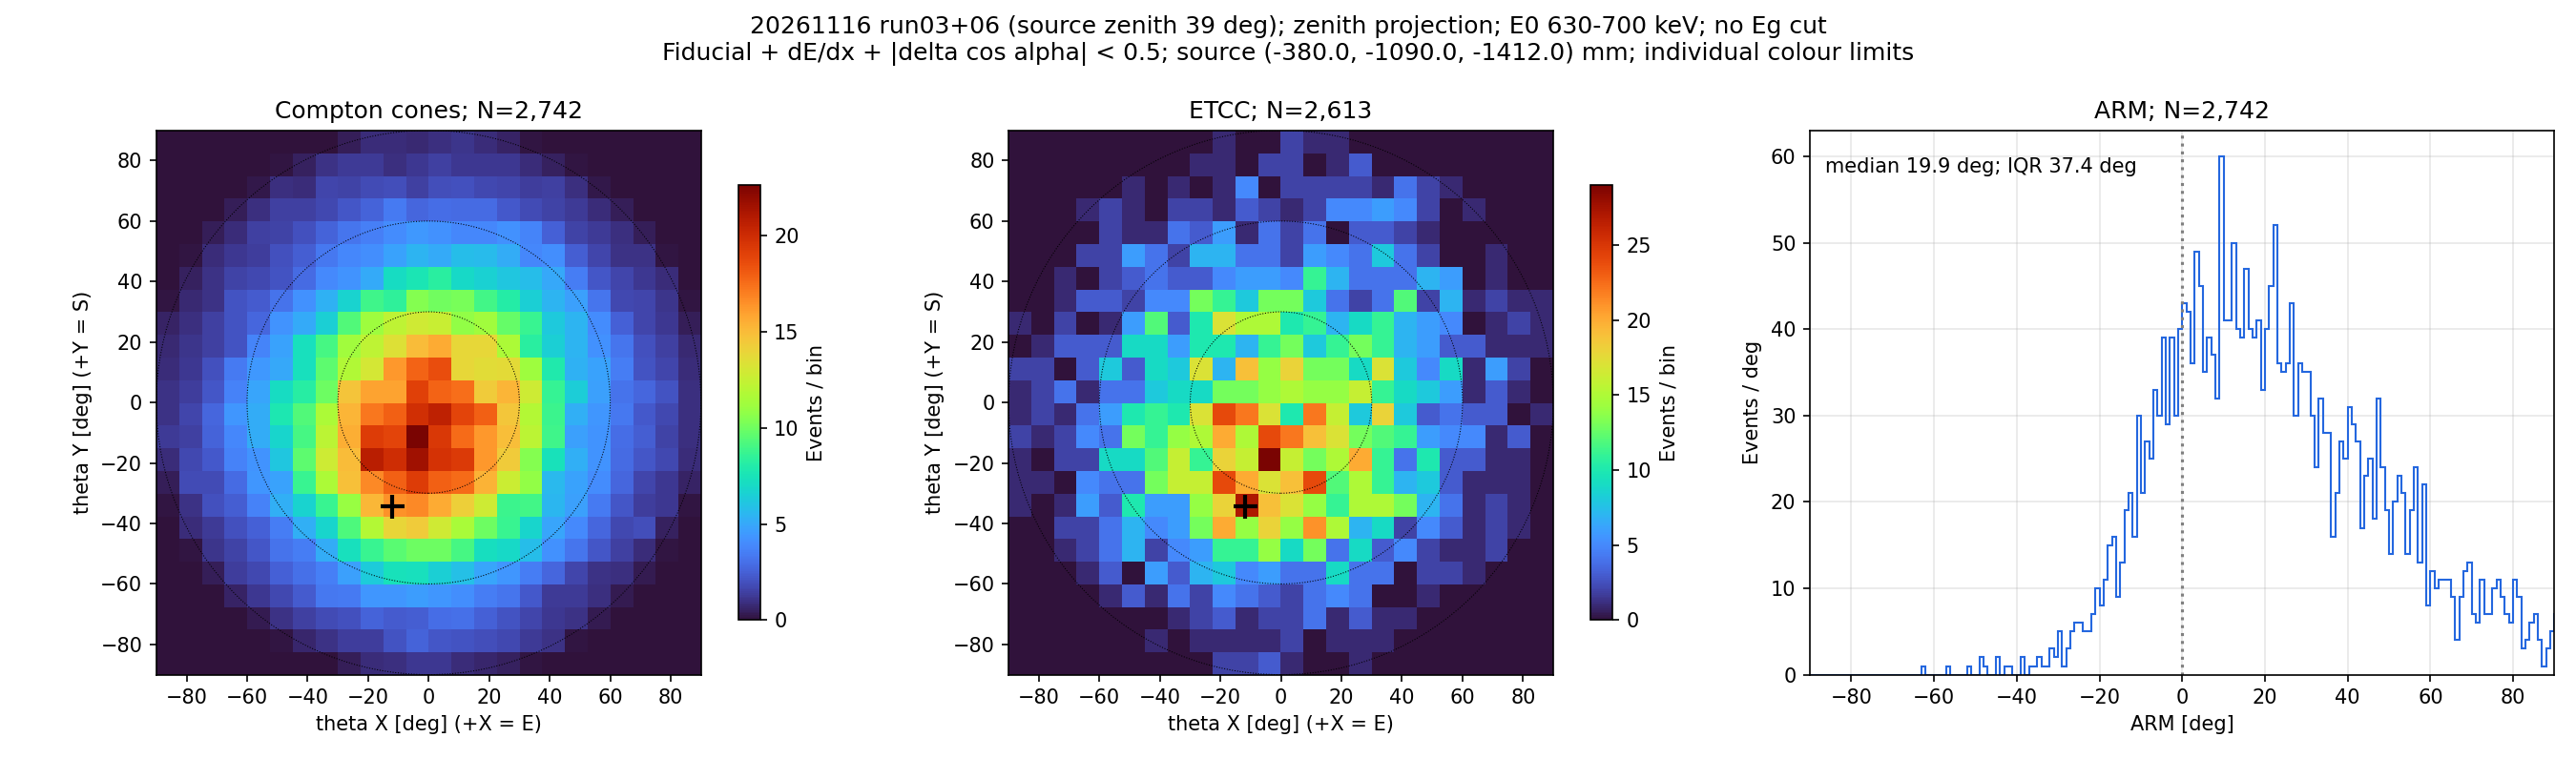

**20261115_run03**

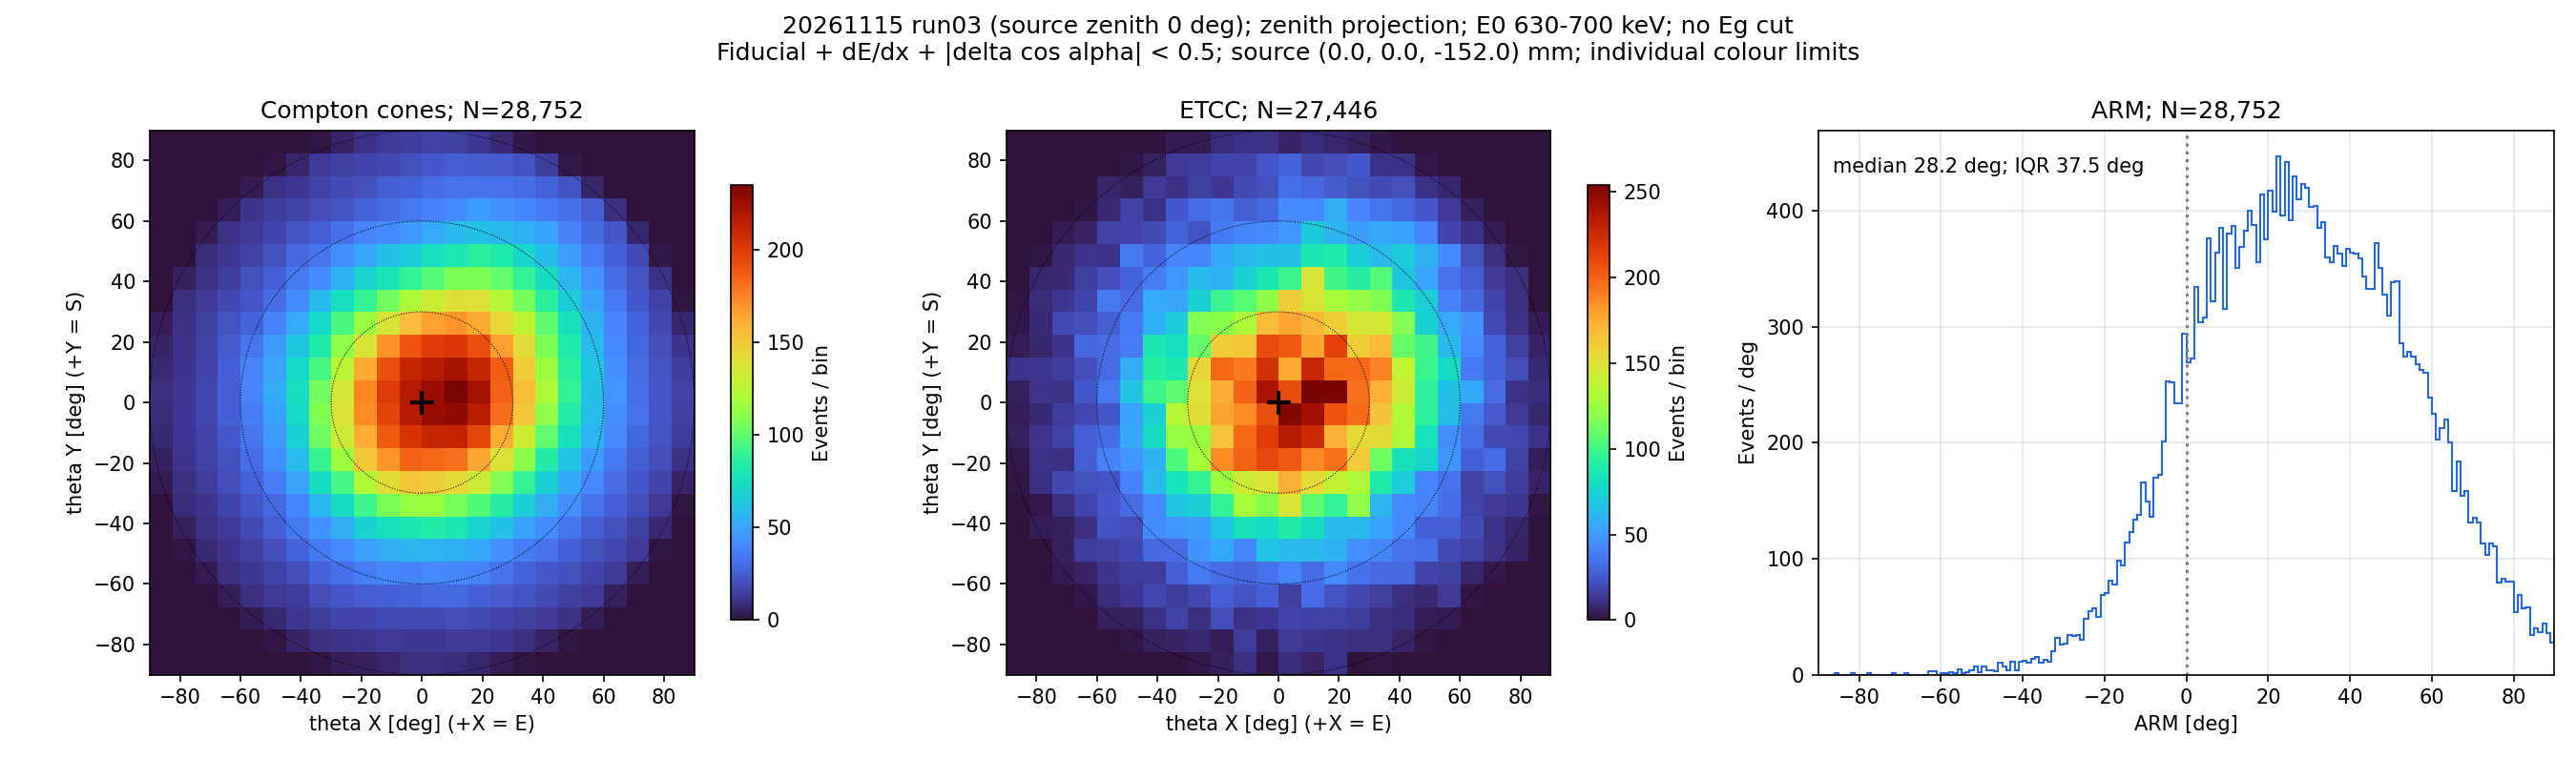

In [8]:
CUT_TO_SHOW = 4
for name in SELECTED_RUNS:
    display(Markdown(f'**{name}**'))
    display(Image(filename=str(OUT / name / f'backprojection_{CUT_TO_SHOW:02d}.png')))

## 解釈するときの確認点

TPC と PSA の座標系は一致すると仮定しています。ピクセルの向き・飛跡方向・較正の妥当性は別に確認が必要です。
カットを加えて件数が減ったことと、ARM の偏りが改善したことを分けて確認してください。
方向図が中心に集まるだけでは正しい再構成と判断せず、実測線源方向、ARM、イベント表示も併せて見ます。
低統計では `SKY_BINS` を小さくし、平滑化で構造を付け加えずにビンをまとめます。

1事象の飛跡を確認する場合は `scripts/analysis/plot_etcc_event.py` を使います。
`--min-len` / `--max-len` [mm]、`--top` [events]、`--order points|length` で自動選択を変更できます。
入力 ROOT は `TOT_Skewness.flag_save_cloud=true` で保存した点群が必要です。

背景だけでも ARM の中央値が正に偏る場合があります。中央値やピークの位置だけで線源信号の有無を判断せず、真の線源位置と回転した偽線源位置の差、または測定時間などで規格化した線源あり・なしの差を確認します。このノートブックは背景を差し引く前の分布です。

今回の較正には次の制約があります（2026-11-17時点）。TPC のゲインマップは576組中230組のみ較正済みで、未較正の寄与は0です。全体の二次補正は負の寄与を除く修正前のスペクトルから決めています。ドリフト速度は run03 の上端の鈍い分布から得た暫定値（品質判定NG）。PSA は温度補正なしで、Cs と Co の較正ランに1〜2 °Cの差があります。これらを含めて較正・背景を確認するまで、分布の幅を装置の性能として扱わないでください。


## 9. Lambert 正積投影でも比較する

ここまでの図は、最初に比較した図と同じ「天頂角を半径にする図」です。
Claude の引き継ぎスクリプトの最新版と同じ Lambert 正積投影も、`--projection lambert` で描けます。

半径は $r=2\sin(\theta/2)$。軸の数値は $r\times180/\pi$（角度そのものではなく degree-equivalent）で、上半球の半径は約81.03です。
同心円は天頂角30、60、90°を示します。平面内の等しい面積が等しい立体角に対応し、天頂角半径図の面積による偏りを避けられます。
円周を横切る部分ビンの面積と検出効率は補正していません。

`MAKE_LAMBERT=False` にすれば、この追加描画は省略できます。カット、入力事象、E0窓は変更しません。
出力は各ランの `lambert/` に置き、元の図も残します。

**20261116_run03_06: Lambert equal-area**

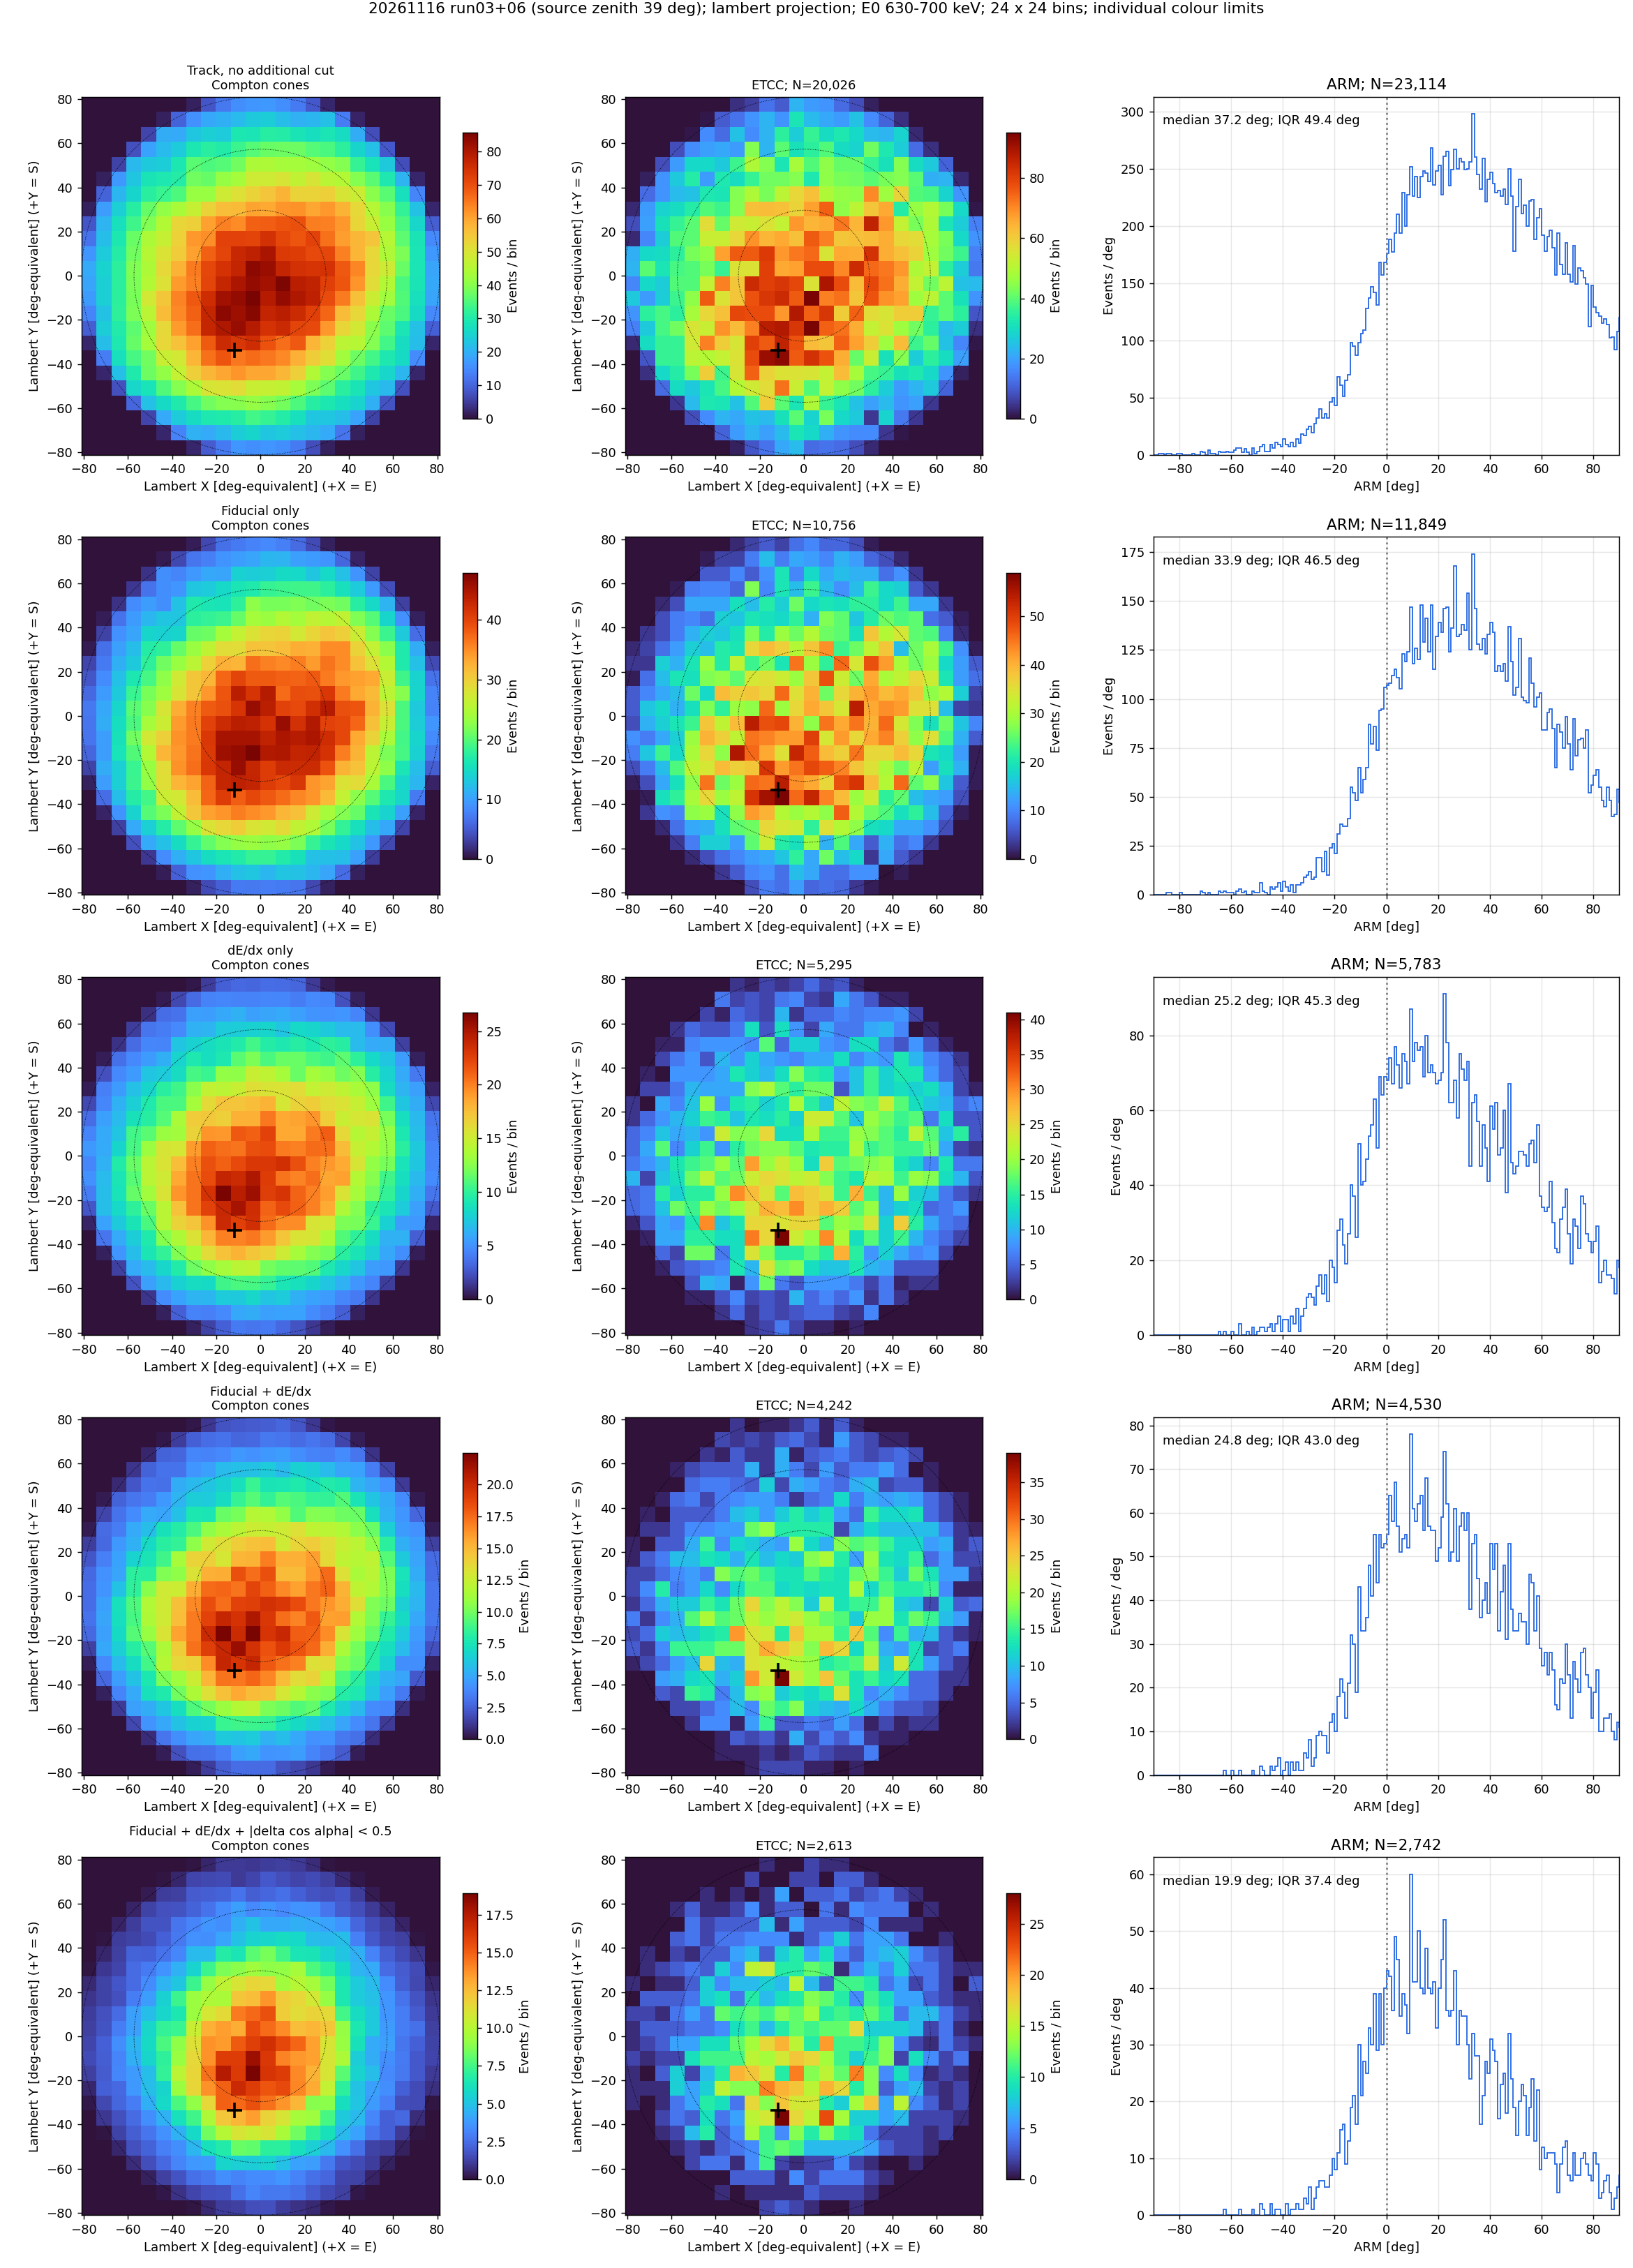

**20261115_run03: Lambert equal-area**

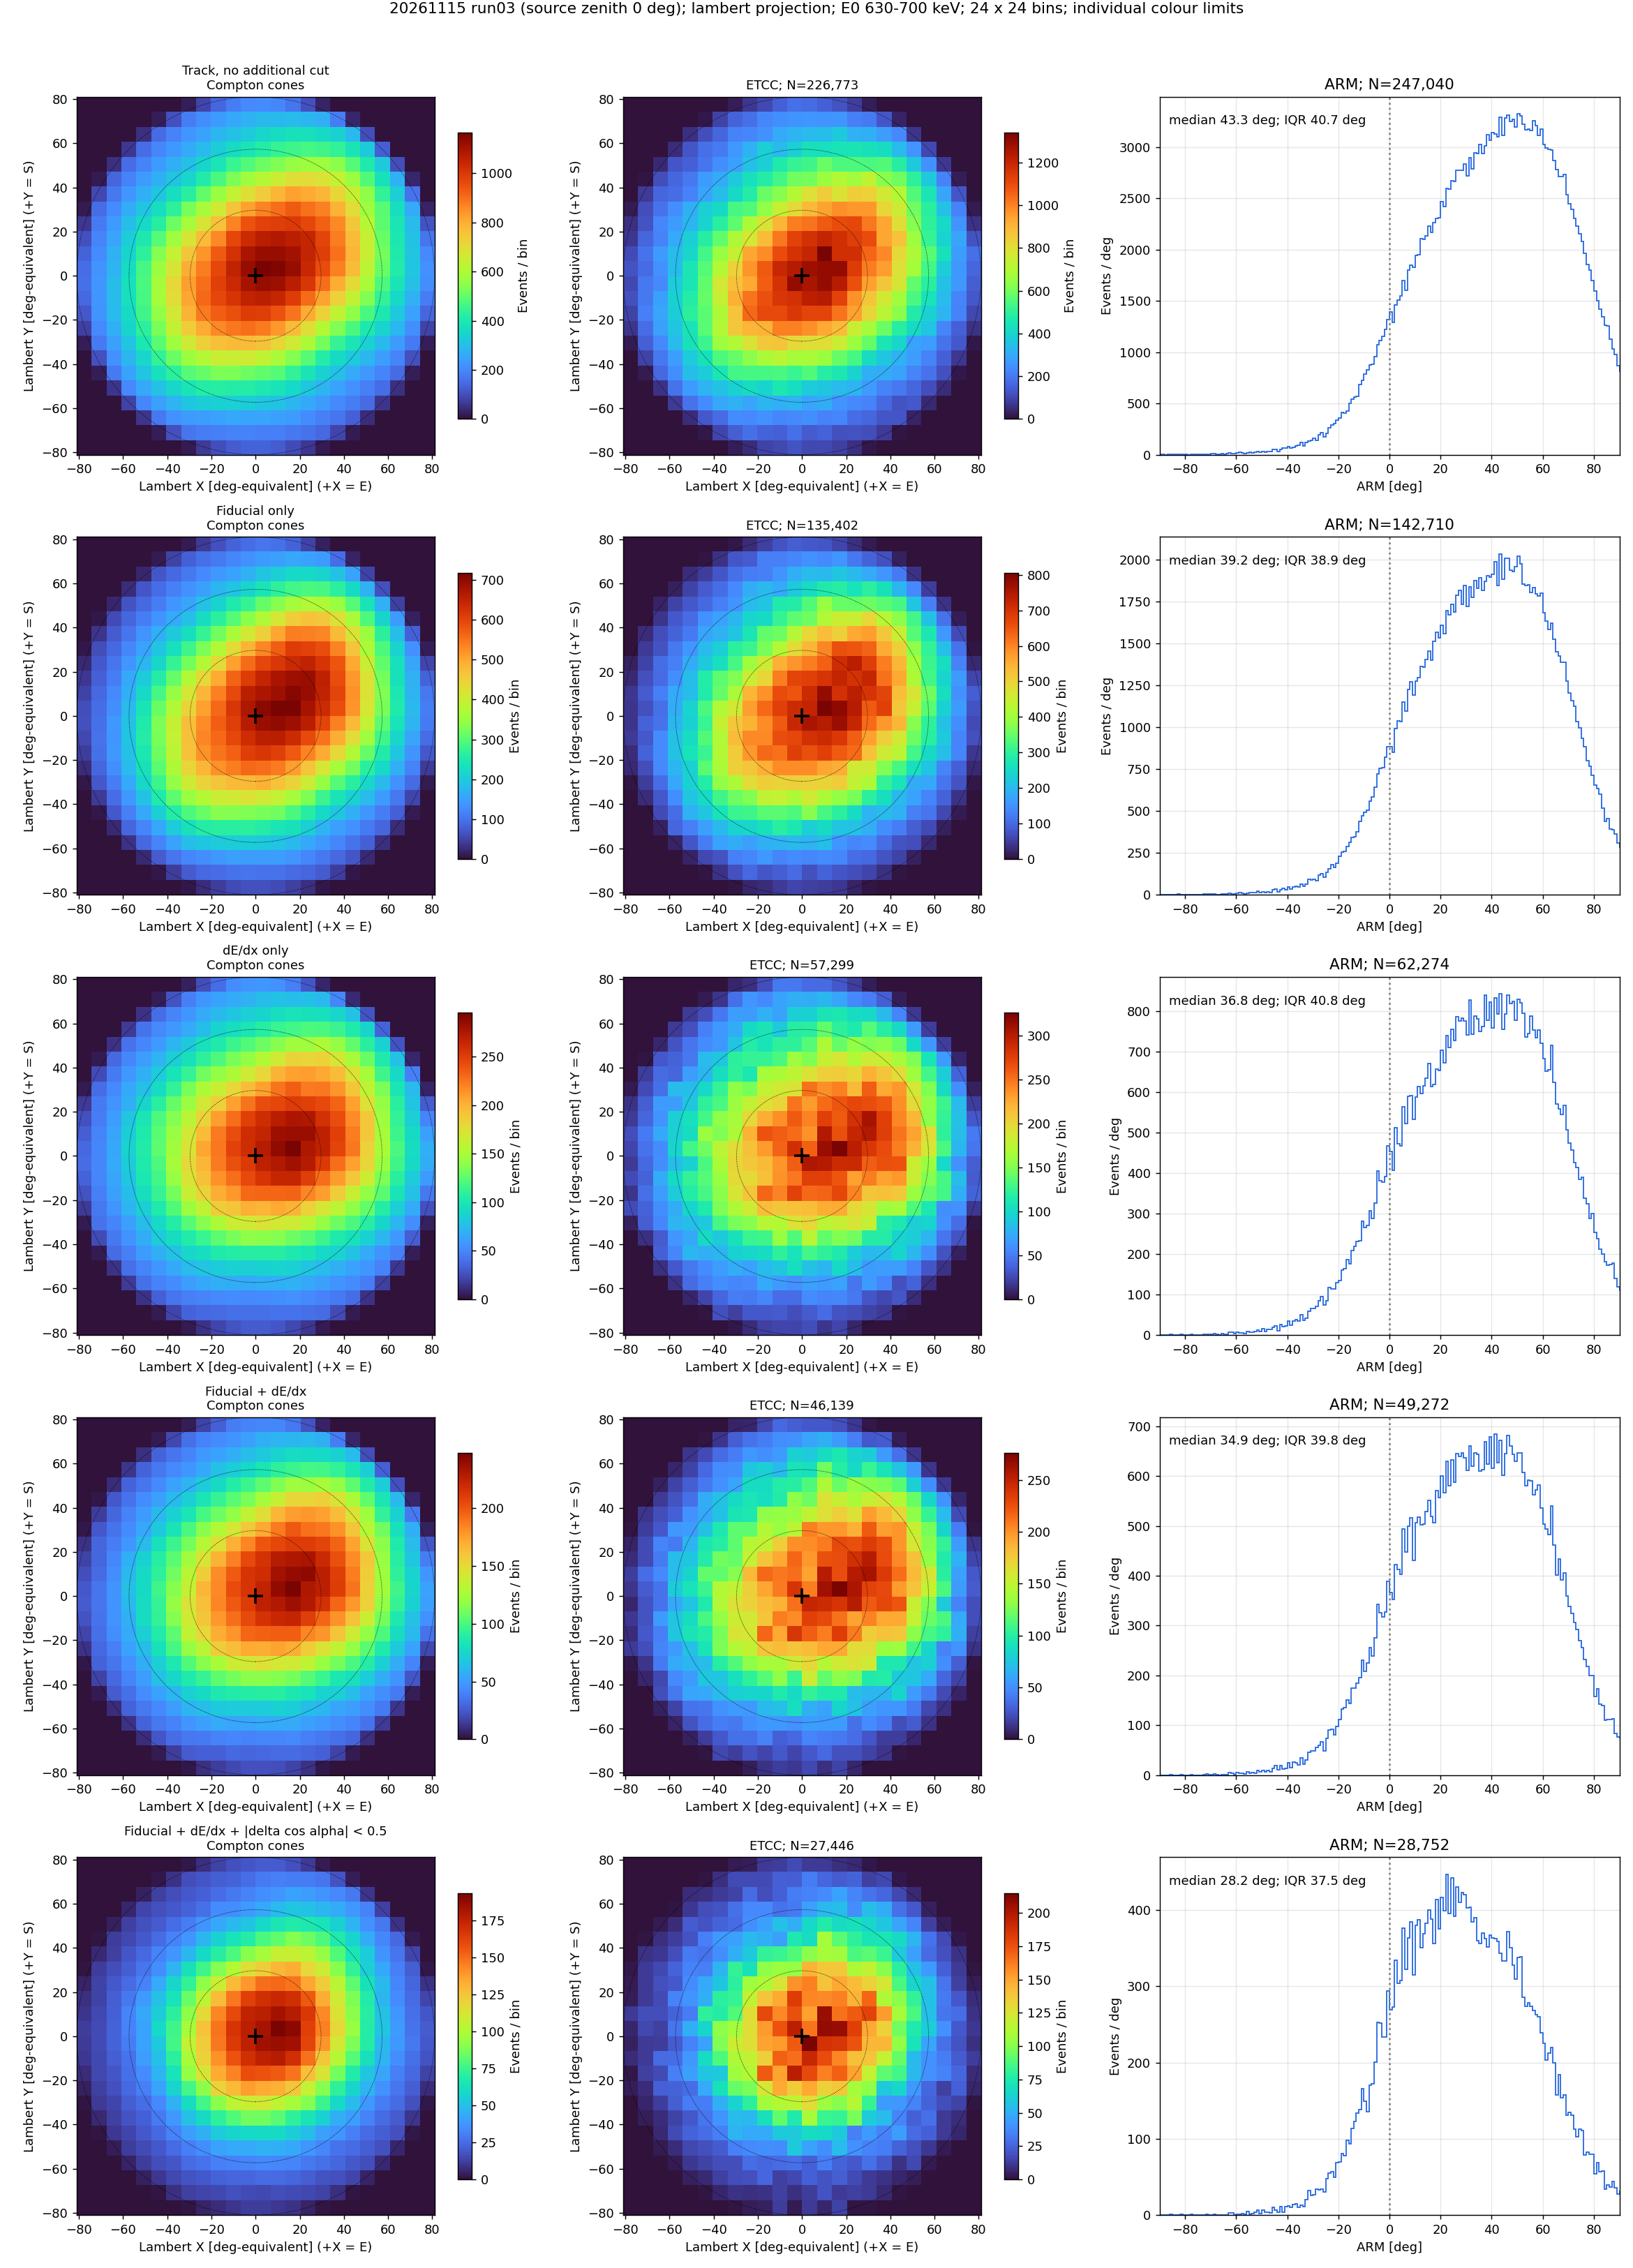

/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run03/etcc_recon_20261116_run03.part000.root 40256 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run03/etcc_recon_20261116_run03.part001.root 39934 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part000.root 56430 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part001.root 56457 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part002.root 46927 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part003.root 16795 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part004.root 18608 single_hit; join OK
/home/onoda/ericanext_out/20261116_v2/etcc_recon_20261116_run06/etcc_recon_20261116_run06.part005

In [9]:
MAKE_LAMBERT = True
if MAKE_LAMBERT:
    for name in SELECTED_RUNS:
        item = DATASETS[name]
        dest = OUT / name / 'lambert'
        cmd = [PYTHON, str(SCRIPT), *INPUTS[name], '--out', str(dest),
               '--src', *map(str, item['source_mm']), '--label', item['label'],
               '--emin', str(MAP_E0_KEV[0]), '--emax', str(MAP_E0_KEV[1]),
               '--alpha', str(ALPHA_MAX_DELTA_COS), '--margin', str(FIDUCIAL_MARGIN_MM),
               '--len-scale', str(LENGTH_SCALE), '--bins', str(SKY_BINS),
               '--projection', 'lambert']
        subprocess.run(cmd, check=True, cwd=REPO)
        lam = json.loads((dest / 'selection_summary.json').read_text())
        for original, projected in zip(SUMMARIES[name]['cuts'], lam['cuts']):
            for key in ['spectrum_events', 'E0_window_events', 'upper_hemisphere_events']:
                assert original[key] == projected[key], (name, key)
        display(Markdown(f'**{name}: Lambert equal-area**'))
        display(Image(filename=str(dest / 'backprojection_cut_comparison_autoscale.png')))